In [1]:
!pip install -q ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 35.1 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 4.1 MB/s eta 0:00:00


In [2]:
import os
from pathlib import Path
from ultralytics import YOLO
from IPython.display import Image, display
import yaml
import shutil
import random

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [3]:
INPUT_DIR = Path("/kaggle/input/ambulance-yolo-dataset")
train_path = INPUT_DIR / "train/images"
val_path = INPUT_DIR / "val/images"

yaml_content = f"""
path: {INPUT_DIR.as_posix()}
train: train/images
val: val/images

nc: 2
names:
  0: emergency
  1: non_emergency
"""

with open("/kaggle/working/data.yaml", "w") as f:
    f.write(yaml_content.strip())

In [4]:
input_root = Path("/kaggle/input")
train_matches = list(input_root.rglob("train/images"))
val_matches = list(input_root.rglob("val/images"))

if not train_matches or not val_matches:
    print("خطا: پوشه‌های train/images یا val/images پیدا نشدند!")
    print("پوشه‌های موجود در input:")
    for p in input_root.rglob("*"):
        if p.is_dir():
            print(" -", p)
    raise FileNotFoundError("ساختار دیتاست در /kaggle/input ناقص است.")

train_path = train_matches[0].resolve().as_posix()
val_path = val_matches[0].resolve().as_posix()

print(f"مسیر دقیق Train پیدا شد: {train_path}")
print(f"مسیر دقیق Val پیدا شد:   {val_path}")

data_config = {
    "train": train_path,
    "val": val_path,
    "nc": 2,
    "names": {
        0: "emergency",
        1: "non_emergency"
    }
}

yaml_path = "/kaggle/working/data.yaml"
with open(yaml_path, "w") as f:
    yaml.dump(data_config, f, default_flow_style=False)

مسیر دقیق Train پیدا شد: /kaggle/input/datasets/aryafbz/ambulance-dataset/train/images
مسیر دقیق Val پیدا شد:   /kaggle/input/datasets/aryafbz/ambulance-dataset/val/images


In [5]:
model = YOLO("yolov8n.pt") 
results = model.train(
    data="/kaggle/working/data.yaml",
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,  
    device=0, 
    mosaic=1.0,
    mixup=0.1,
    degrees=10.0,
    fliplr=0.5,
    project="/kaggle/working/runs",
    name="ambulance_detector",
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=10.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=ambulance_detector, nbs=64, nms=None, opset=None, optimize=Fal

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/60      2.55G      1.255      1.528      1.608         63        640: 100% ━━━━━━━━━━━━ 64/64 7.3it/s 8.8s0.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.2it/s 1.7s0.2s
                   all        257        361      0.651      0.679      0.711      0.331

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      2.55G      1.271      1.418      1.621         42        640: 100% ━━━━━━━━━━━━ 64/64 7.5it/s 8.6s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 5.5it/s 1.6s0.2s
                   all        257        361       0.37      0.575        0.4      0.191

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/60      2.55G       1.29      1.368       1.64         43        640: 100% ━━━━━━━━━━━━ 64/64 7.4it/s 8.6s0.3s
                 Class     Images  Instances  

In [9]:
best_model = YOLO("/kaggle/working/runs/ambulance_detector/weights/best.pt")

metrics = best_model.val(data="/kaggle/working/data.yaml")

print(f"کلی - mAP50:    {metrics.box.map50:.3f}")
print(f"کلی - mAP50-95: {metrics.box.map:.3f}")

for i, class_name in enumerate(metrics.names.values()):
    p = metrics.box.p[i]  # Precision
    r = metrics.box.r[i]  # Recall
    ap50 = metrics.box.ap50[i]  # mAP@0.5
    print(f"\nکلاس: {class_name}")
    print(f"  Precision: {p:.3f}")
    print(f"  Recall:    {r:.3f}")
    print(f"  mAP50:     {ap50:.3f}")

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Model summary (fused): 72 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.4±0.5 ms, read: 16.6±8.1 MB/s, size: 13.4 KB)
val: Scanning /kaggle/input/datasets/aryafbz/ambulance-dataset/val/labels... 257 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 257/257 709.3it/s 0.4s0.1s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/aryafbz/ambulance-dataset/val is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 5.0it/s 3.4s0.1s
                   all        257        361      0.965      0.938      0.977      0.751
             emergency         53         60      0.949      0.967      0.976      0.754
         non_emergency        204        301      0.981       0.91      0.978      0.748
Speed: 1.3ms preprocess, 5.5ms inference, 0.0ms loss, 1.7ms postprocess per ima

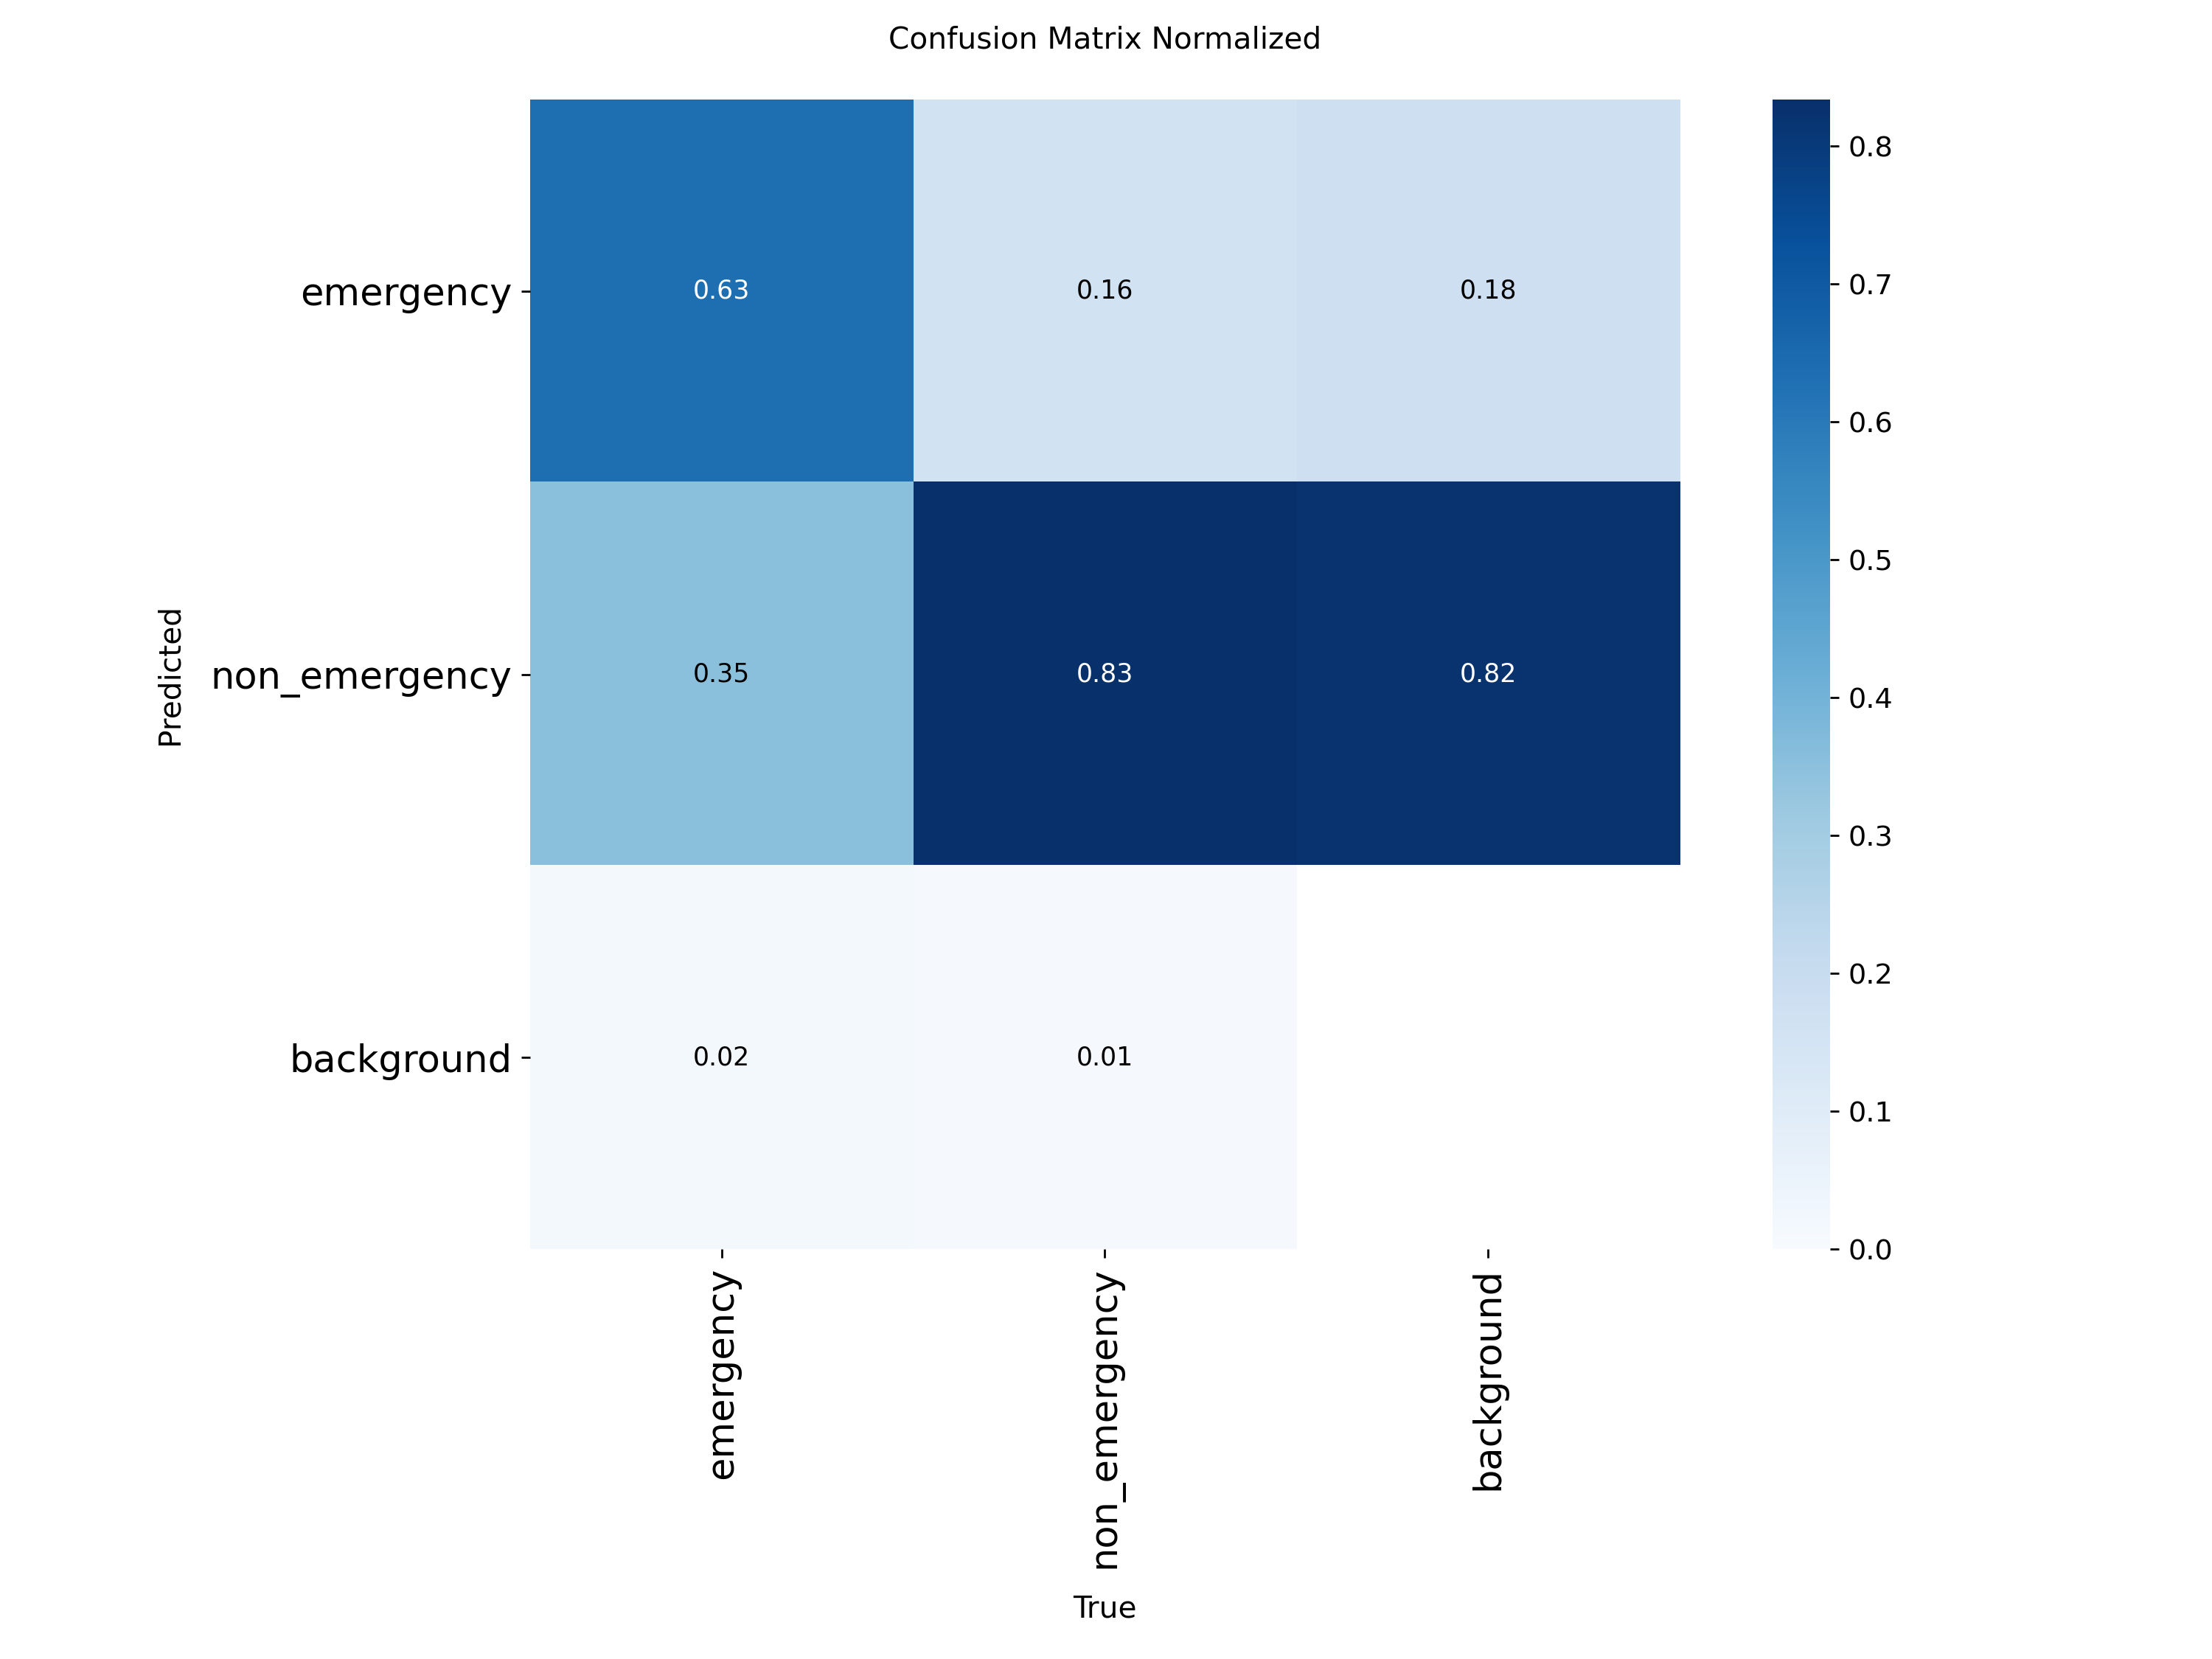

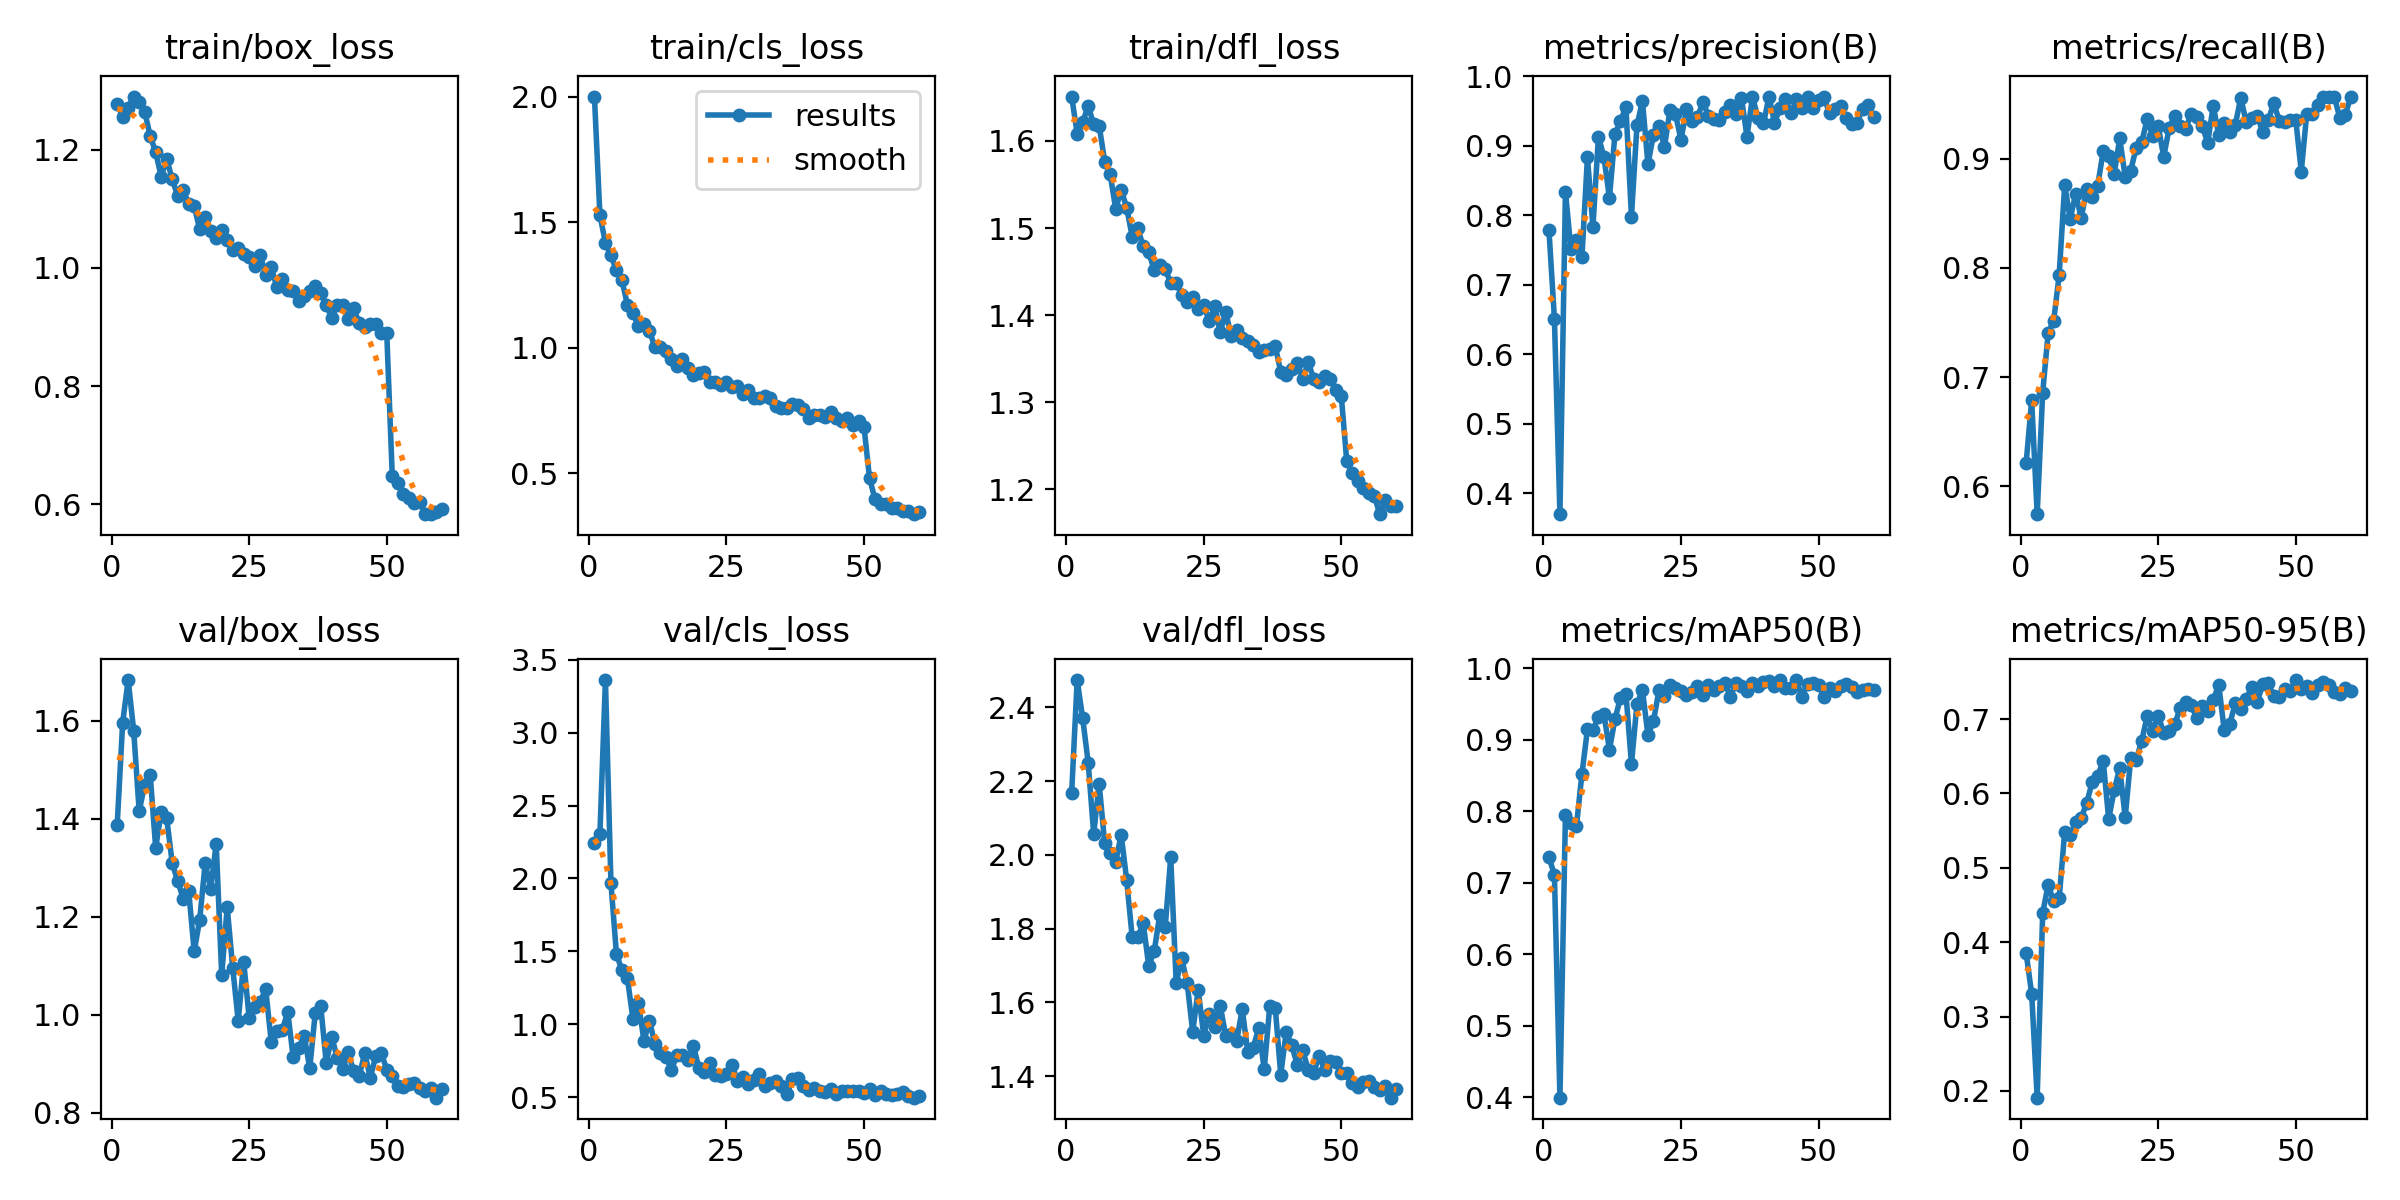

In [6]:
run_dir = "/kaggle/working/runs/ambulance_detector"

display(Image(filename=f"{run_dir}/confusion_matrix_normalized.png"))

display(Image(filename=f"{run_dir}/results.png"))

In [7]:
model = YOLO("yolov8s.pt")

results = model.train(
    data="/kaggle/working/data.yaml",  
    epochs=60,
    imgsz=640,
    batch=16,
    patience=15,
    device=0,
    mosaic=1.0,
    mixup=0.2,
    copy_paste=0.1,
    degrees=15.0,
    scale=0.6,
    project="/kaggle/working/runs",
    name="full_dataset_yolov8s",
    exist_ok=True,
)

Ultralytics 8.4.174 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=15.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.2, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=full_dataset_yolov8s, nbs=64, nms=None, opset=None, optimize=Fa

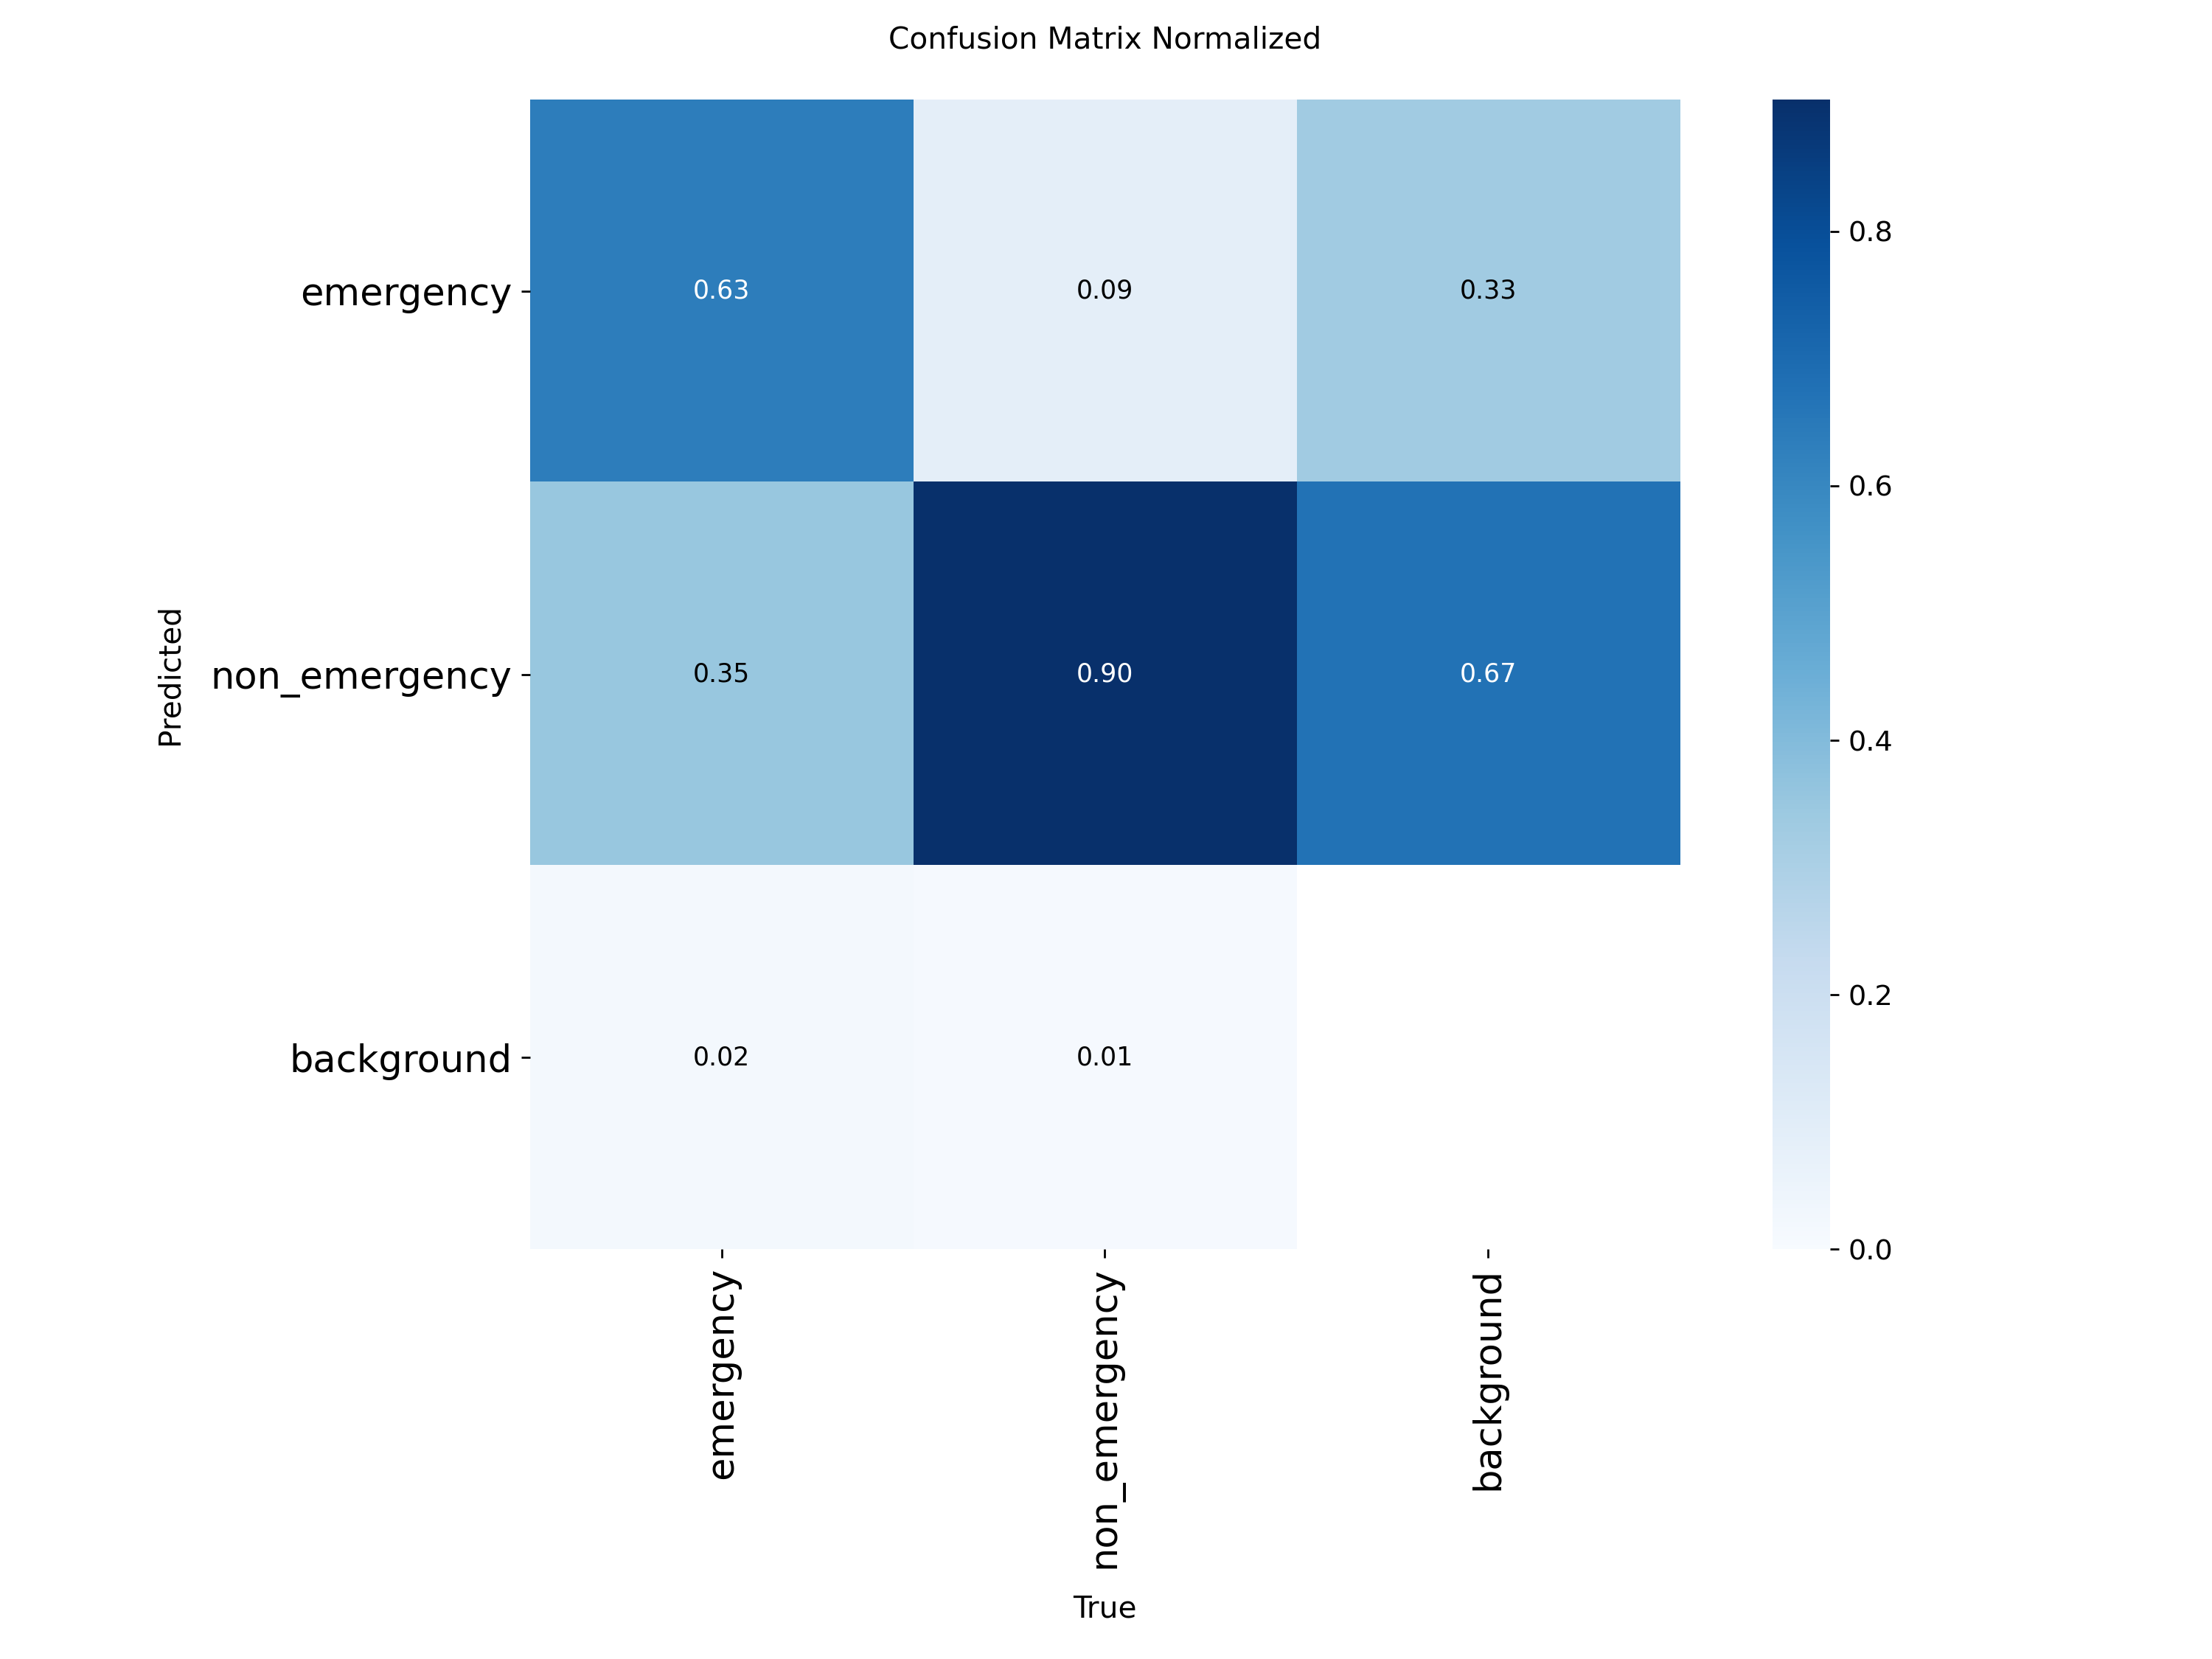

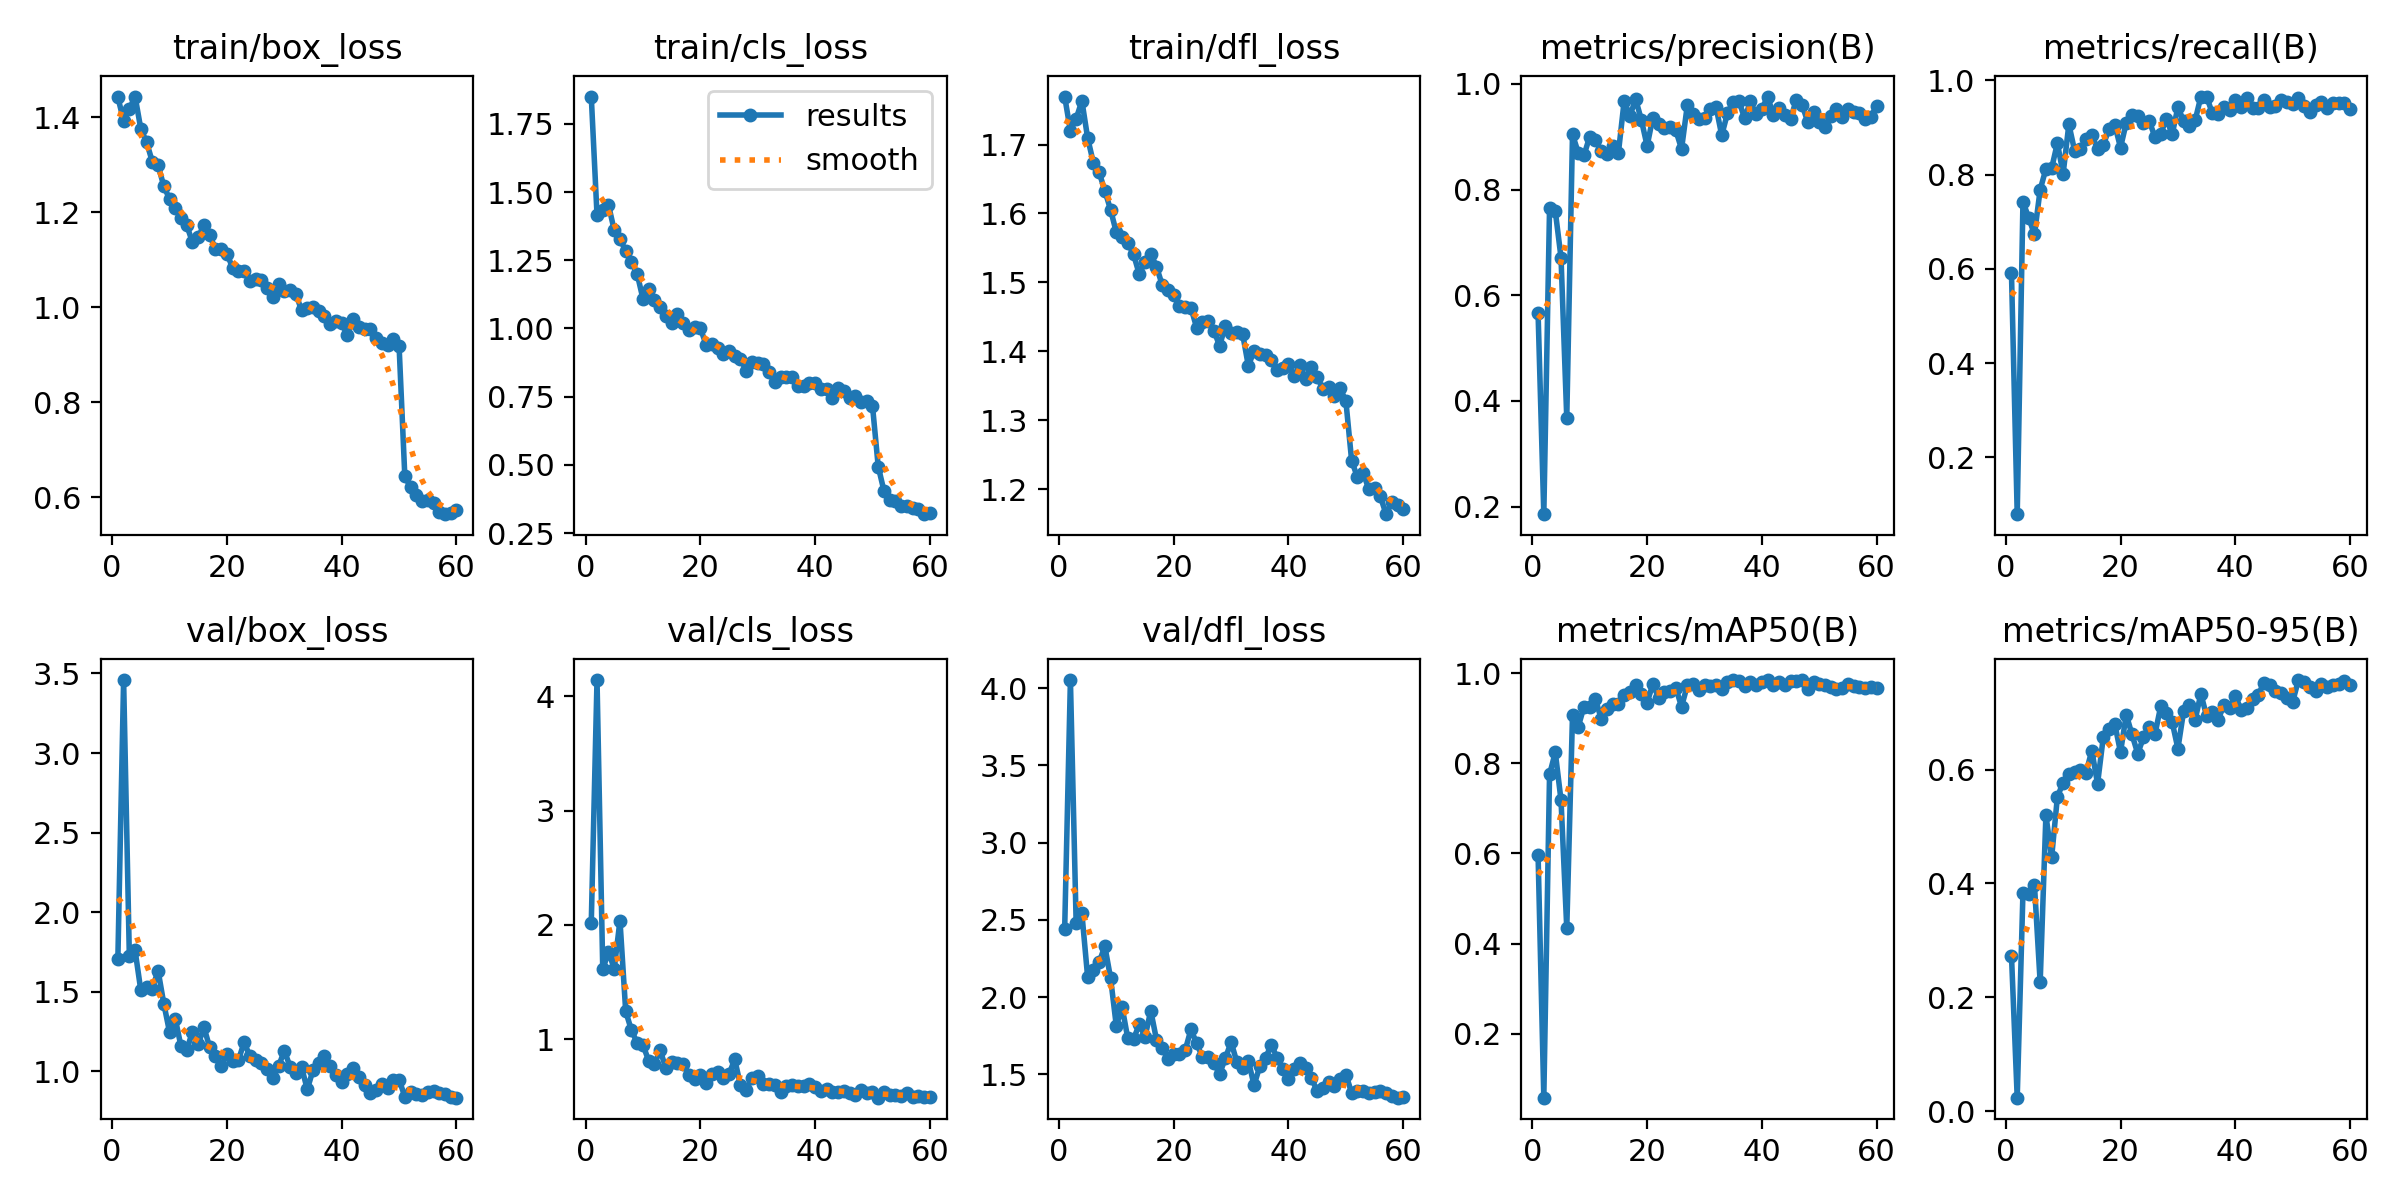

In [8]:
run_dir = "/kaggle/working/runs/full_dataset_yolov8s"

display(Image(filename=f"{run_dir}/confusion_matrix_normalized.png"))

display(Image(filename=f"{run_dir}/results.png"))